In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_excel("/content/Olist_Sample  Final Project Data.xlsx")

In [ ]:
from pandas.io import excel
file_path = "/content/Olist_Sample  Final Project Data.xlsx"

excel_file = pd.ExcelFile(file_path)

print("Number of sheets:", len(excel_file.sheet_names))
print("\nSheet names:")

for sheet_name in excel_file.sheet_names:
    print(sheet_name)

Number of sheets: 8

Sheet names:
Orders
Order_Items
Payments
Reviews
Customers
Products
Sellers
Translation


In [ ]:
# load all sheets into dictionary

data = pd.read_excel(file_path, sheet_name=None)


# Check data quality for each Sheet


for sheet_name, sheet_data in data.items():

  print(f"\n{'=' * 50}")

  print(f"Sheet:{sheet_name}")

  print("Rows and columns:", df.shape)

  print("Missing Values:", df.isna().sum().sum())

  print("Duplicate rows:", df.duplicated().sum())

  print("Duplicated columns names:", df.columns.duplicated().sum())


Sheet:Orders
Rows and columns: (8002, 8)
Missing Values: 422
Duplicate rows: 0
Duplicated columns names: 0

Sheet:Order_Items
Rows and columns: (8002, 8)
Missing Values: 422
Duplicate rows: 0
Duplicated columns names: 0

Sheet:Payments
Rows and columns: (8002, 8)
Missing Values: 422
Duplicate rows: 0
Duplicated columns names: 0

Sheet:Reviews
Rows and columns: (8002, 8)
Missing Values: 422
Duplicate rows: 0
Duplicated columns names: 0

Sheet:Customers
Rows and columns: (8002, 8)
Missing Values: 422
Duplicate rows: 0
Duplicated columns names: 0

Sheet:Products
Rows and columns: (8002, 8)
Missing Values: 422
Duplicate rows: 0
Duplicated columns names: 0

Sheet:Sellers
Rows and columns: (8002, 8)
Missing Values: 422
Duplicate rows: 0
Duplicated columns names: 0

Sheet:Translation
Rows and columns: (8002, 8)
Missing Values: 422
Duplicate rows: 0
Duplicated columns names: 0


In [ ]:
## 4. Dataset Validation


for sheet_name, df in data.items():

  print(f"\n{'=' * 50}")

  print(f"Sheet:{sheet_name}")

  print("Shape:", df.shape)

  print("Columns:", df.columns.tolist())

  print(df.head(3))




Sheet:Orders
Shape: (8002, 8)
Columns: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
                           order_id                       customer_id  \
0  6acecf438369055d9243e121045cca74  42d857e22f61f10476f0cda1aacc018a   
1  1b694ef5b28d3e949a4f0ffeb2c9fcd6  cba12036a88407a37770dc8ab725de77   
2  2f9d791088532b218b41f892cc16073b  937bb74713a47912471275b234236764   

  order_status order_purchase_timestamp   order_approved_at  \
0    delivered      2017-01-05 12:11:23 2017-01-07 03:44:07   
1    delivered      2017-01-05 13:43:17 2017-01-07 03:35:38   
2    delivered      2017-01-05 13:48:48 2017-01-07 03:35:21   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-01-11 16:22:53           2017-01-17 16:06:30   
1          2017-01-11 16:08:55           2017-01-16 16:54:04   
2          2017-01-11 16:08:53 

In [ ]:
##5. Missing Values

#Analyze missing values in every sheet


for sheet_name, df in data.items():
    missing_count = df.isnull().sum()
    missing_percent = (missing_count / len(df)) * 100


    missing_report = pd.DataFrame({
        "Missing Count": missing_count,
        "Missing Percentage": missing_percent.round(2)
    })

# Display only columns with missing values
missing_report = missing_report[missing_report["Missing Count"] > 0].sort_values(by="Missing Count", ascending=False)

print(f"\n{'=' * 60}")
print(f"Sheet: {sheet_name}")


if missing_report.empty:
    print("No missing values found.")


else:
    display(missing_report)








Sheet: Translation
No missing values found.


In [ ]:
#Missing Values Summarize


summary = []

for sheet_name, df in data.items():
  total_missing = df.isnull().sum().sum()
  total_cells = df.size


  summary.append({
      "Sheet": sheet_name,
      "Rows": df.shape[0],
      "Columns": df.shape[1],
      "Total Missing": total_missing,
      "Missing Percentage": (total_missing / total_cells) * 100
  })


  missing_summary = pd.DataFrame(summary)

  display(missing_summary)



,Sheet,Rows,Columns,Total Missing,Missing Percentage
0,Orders,8002,8,422,0.65921


,Sheet,Rows,Columns,Total Missing,Missing Percentage
0,Orders,8002,8,422,0.65921
1,Order_Items,8942,7,0,0.00000


,Sheet,Rows,Columns,Total Missing,Missing Percentage
0,Orders,8002,8,422,0.65921
1,Order_Items,8942,7,0,0.00000
2,Payments,8406,5,0,0.00000


,Sheet,Rows,Columns,Total Missing,Missing Percentage
0,Orders,8002,8,422,0.659210
1,Order_Items,8942,7,0,0.000000
2,Payments,8406,5,0,0.000000
3,Reviews,7986,7,11692,20.915173


,Sheet,Rows,Columns,Total Missing,Missing Percentage
0,Orders,8002,8,422,0.659210
1,Order_Items,8942,7,0,0.000000
2,Payments,8406,5,0,0.000000
3,Reviews,7986,7,11692,20.915173
4,Customers,8002,5,0,0.000000


,Sheet,Rows,Columns,Total Missing,Missing Percentage
0,Orders,8002,8,422,0.659210
1,Order_Items,8942,7,0,0.000000
2,Payments,8406,5,0,0.000000
3,Reviews,7986,7,11692,20.915173
4,Customers,8002,5,0,0.000000
5,Products,5622,9,372,0.735207


,Sheet,Rows,Columns,Total Missing,Missing Percentage
0,Orders,8002,8,422,0.659210
1,Order_Items,8942,7,0,0.000000
2,Payments,8406,5,0,0.000000
3,Reviews,7986,7,11692,20.915173
4,Customers,8002,5,0,0.000000
5,Products,5622,9,372,0.735207
6,Sellers,1491,4,0,0.000000


,Sheet,Rows,Columns,Total Missing,Missing Percentage
0,Orders,8002,8,422,0.659210
1,Order_Items,8942,7,0,0.000000
2,Payments,8406,5,0,0.000000
3,Reviews,7986,7,11692,20.915173
4,Customers,8002,5,0,0.000000
5,Products,5622,9,372,0.735207
6,Sellers,1491,4,0,0.000000
7,Translation,71,2,0,0.000000


In [ ]:

##5.2 Missing Values by Column

#Inspect missing values in Orders and Reviews


for sheet_name in ["Orders", "Reviews"]:
  df = data[sheet_name]


  missing_report = pd.DataFrame({
      "Missing Count": df.isnull().sum(),
      "Missing Percentage": (df.isnull().sum() / len(df) * 100
      ).round(2)
  })

  missing_report = missing_report[
     missing_report["Missing Count"] > 0
 ].sort_values(by="Missing Count", ascending=False)

  print(f"\nMissing Values for {sheet_name}")
  display(missing_report)


Missing Values for Orders


,Missing Count,Missing Percentage
order_delivered_customer_date,257,3.21
order_delivered_carrier_date,149,1.86
order_approved_at,16,0.20



Missing Values for Reviews


,Missing Count,Missing Percentage
review_comment_title,7034,88.08
review_comment_message,4658,58.33


In [ ]:
##5.3 Investigating Missing Order Date


orders_df = data["Orders"]


for column in [
    "order_approved_at",
    "order_deliverd_carrier_date",
    "order_delivered_customer_date"
]:

  print(f"\n Missing Values in {column} by order statues:")

missing_by_status = (
    orders_df[orders_df[column].isna()]
    ["order_status"]
    .value_counts()
)

display(missing_by_status.to_frame("Missing Count"))


 Missing Values in order_approved_at by order statues:

 Missing Values in order_deliverd_carrier_date by order statues:

 Missing Values in order_delivered_customer_date by order statues:


,Missing Count
order_status,
shipped,104
unavailable,56
canceled,47
processing,29
invoiced,20
delivered,1


In [ ]:
##5.4 Investigating Inconsistant Delivery Records


delivered_missing = orders_df[
    (orders_df["order_status"] == "delivered") &
    (orders_df["order_delivered_customer_date"].isna())
]

display(delivered_missing)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
6756,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16


In [ ]:
##5.5 Duplicate Records Analysis
import pandas as pd

# Ensure 'data' is loaded
if 'data' not in globals():
    file_path = "/content/Olist_Sample  Final Project Data.xlsx"
    data = pd.read_excel(file_path, sheet_name=None)

# Check Duplicate Rows in All Sheets
for sheet_name, df in data.items():
    duplicate_count = df.duplicated().sum()
    print(f"{sheet_name}: {duplicate_count} duplicated rows")

# Check Duplicate Review IDs and Repeated Order IDs
reviews_df = data["Reviews"]

print("\nDuplicate review_id:")
print(reviews_df["review_id"].duplicated().sum())

print("\nRepeated order_id:")
print(reviews_df["order_id"].duplicated().sum())

print("\nRepeated review_id Records:")
display(
    reviews_df[
        reviews_df["review_id"].duplicated(keep=False)
    ].sort_values("review_id")
)






Orders: 0 duplicated rows
Order_Items: 0 duplicated rows
Payments: 0 duplicated rows
Reviews: 0 duplicated rows
Customers: 0 duplicated rows
Products: 0 duplicated rows
Sellers: 0 duplicated rows
Translation: 0 duplicated rows

Duplicate review_id:
8

Repeated order_id:
50

Repeated review_id Records:


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
707,183808dc516fab3df74b087310299cf0,374a125372cffb30e8e2df55f8448da4,5,NaN,"Ainda não usei o produto, mas em relação à ent...",2018-02-07 00:00:00,2018-02-08 01:17:50
7867,183808dc516fab3df74b087310299cf0,29210b1d48462ce1f12d87ed7ccd6397,5,NaN,"Ainda não usei o produto, mas em relação à ent...",2018-02-07 00:00:00,2018-02-08 01:17:50
2168,5e78482ee783451be6026e5cf0c72de1,ff763b73e473d03c321bcd5a053316e8,3,NaN,Não sei que haverá acontecido os demais chegaram,2017-11-18 00:00:00,2017-11-18 09:02:48
7378,5e78482ee783451be6026e5cf0c72de1,ccfa13cff25aa5ad005e434ac68acaaa,3,NaN,Não sei que haverá acontecido os demais chegaram,2017-11-18 00:00:00,2017-11-18 09:02:48
354,72a1098d5b410ae50fbc0509d26daeb9,566f53fc7d36fa366f7e221468121877,5,NaN,NaN,2017-02-07 00:00:00,2017-02-10 10:46:09
1105,72a1098d5b410ae50fbc0509d26daeb9,df56136b8031ecd28e200bb18e6ddb2e,5,NaN,NaN,2017-02-07 00:00:00,2017-02-10 10:46:09
243,aa193e76d35950c4ae988237bb36ed2b,cf73e2cb1f4a9480ed70c154da3d954a,5,NaN,NaN,2018-01-18 00:00:00,2018-01-18 17:36:45
2444,aa193e76d35950c4ae988237bb36ed2b,fc9d6087c02b8f60e1a365a3b6ae786e,5,NaN,NaN,2018-01-18 00:00:00,2018-01-18 17:36:45
229,c444278834184f72b1484dfe47de7f97,df56136b8031ecd28e200bb18e6ddb2e,5,NaN,NaN,2017-02-08 00:00:00,2017-02-14 13:58:48
3518,c444278834184f72b1484dfe47de7f97,566f53fc7d36fa366f7e221468121877,5,NaN,NaN,2017-02-08 00:00:00,2017-02-14 13:58:48


In [ ]:

# Detailed Review ID Duplicate Analysis

duplicate_reviews = reviews_df[
    reviews_df["review_id"].duplicated(keep=False)
].sort_values("review_id")

print("Number of duplicated review IDs:")
print(duplicate_reviews["review_id"].nunique())

print("\nDetailed duplicated review records:")
display(
    duplicate_reviews[
        [
            "review_id",
            "order_id",
            "review_score",
            "review_creation_date",
            "review_answer_timestamp"
        ]
    ]
)

Number of duplicated review IDs:
8

Detailed duplicated review records:


,review_id,order_id,review_score,review_creation_date,review_answer_timestamp
707,183808dc516fab3df74b087310299cf0,374a125372cffb30e8e2df55f8448da4,5,2018-02-07 00:00:00,2018-02-08 01:17:50
7867,183808dc516fab3df74b087310299cf0,29210b1d48462ce1f12d87ed7ccd6397,5,2018-02-07 00:00:00,2018-02-08 01:17:50
2168,5e78482ee783451be6026e5cf0c72de1,ff763b73e473d03c321bcd5a053316e8,3,2017-11-18 00:00:00,2017-11-18 09:02:48
7378,5e78482ee783451be6026e5cf0c72de1,ccfa13cff25aa5ad005e434ac68acaaa,3,2017-11-18 00:00:00,2017-11-18 09:02:48
354,72a1098d5b410ae50fbc0509d26daeb9,566f53fc7d36fa366f7e221468121877,5,2017-02-07 00:00:00,2017-02-10 10:46:09
1105,72a1098d5b410ae50fbc0509d26daeb9,df56136b8031ecd28e200bb18e6ddb2e,5,2017-02-07 00:00:00,2017-02-10 10:46:09
243,aa193e76d35950c4ae988237bb36ed2b,cf73e2cb1f4a9480ed70c154da3d954a,5,2018-01-18 00:00:00,2018-01-18 17:36:45
2444,aa193e76d35950c4ae988237bb36ed2b,fc9d6087c02b8f60e1a365a3b6ae786e,5,2018-01-18 00:00:00,2018-01-18 17:36:45
229,c444278834184f72b1484dfe47de7f97,df56136b8031ecd28e200bb18e6ddb2e,5,2017-02-08 00:00:00,2017-02-14 13:58:48
3518,c444278834184f72b1484dfe47de7f97,566f53fc7d36fa366f7e221468121877,5,2017-02-08 00:00:00,2017-02-14 13:58:48


In [ ]:
# Compare Duplicate Review Records

# Columns to compare (excluding IDs)
compare_columns = [
    col for col in reviews_df.columns
    if col not in ["review_id", "order_id"]
]

# Check differences between records with the same review_id
duplicate_comparison = (
    duplicate_reviews
    .groupby("review_id")[compare_columns]
    .nunique(dropna=False)
)

print("Duplicate Review Comparison:")
display(duplicate_comparison)

# Identify review IDs with differences
different_reviews = duplicate_comparison[
    (duplicate_comparison > 1).any(axis=1)
]

print("\nNumber of Review IDs with different data:",
      len(different_reviews))

print("\nReview IDs with differences:")
display(different_reviews)

Duplicate Review Comparison:


,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
review_id,,,,,
183808dc516fab3df74b087310299cf0,1,1,1,1,1
5e78482ee783451be6026e5cf0c72de1,1,1,1,1,1
72a1098d5b410ae50fbc0509d26daeb9,1,1,1,1,1
aa193e76d35950c4ae988237bb36ed2b,1,1,1,1,1
c444278834184f72b1484dfe47de7f97,1,1,1,1,1
c56a88a404315a0d9e412c1472dda2c4,1,1,1,1,1
c880f17947402374c0312bea411a7e18,1,1,1,1,1
e4e50748d2d683f0d3de0b2089265b22,1,1,1,1,1



Number of Review IDs with different data: 0

Review IDs with differences:


,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
review_id,,,,,


In [ ]:
# 5.5.1 Repeated Order ID Analysis

repeated_orders = reviews_df[
    reviews_df["order_id"].duplicated(keep=False)
].sort_values("order_id")

print("Number of repeated order IDs:")
print(repeated_orders["order_id"].nunique())

print("\nRepeated Order ID Records:")
display(
    repeated_orders[
        [
            "order_id",
            "review_id",
            "review_score",
            "review_creation_date",
            "review_answer_timestamp"
        ]
    ]
)

Number of repeated order IDs:
49

Repeated Order ID Records:


,order_id,review_id,review_score,review_creation_date,review_answer_timestamp
3093,03515a836bb855b03f7df9dee520a8fc,1dee9d450a2b8533d2085cef898ca4a2,5,2018-02-06 00:00:00,2018-02-06 17:19:21
3983,03515a836bb855b03f7df9dee520a8fc,5e1ee2e924a1dd10d80b99555383c0a7,5,2018-01-31 00:00:00,2018-02-01 01:26:24
136,0715dfcf2383aa72c181d8b47f6cb589,93bff38e529369b84919d539aa3dc449,5,2018-02-28 00:00:00,2018-03-06 23:17:46
868,0715dfcf2383aa72c181d8b47f6cb589,e8ea3d83611914b5a445adbdd5c37072,5,2018-03-10 00:00:00,2018-03-10 20:42:13
1210,14f6c86b695ea4ddd3dd4386d10388b0,948c1093fc5e0db2081ce9f9b4a1bf82,5,2017-06-13 00:00:00,2017-06-14 11:48:09
...,...,...,...,...,...
2353,ed81dbeb0cedad4d3d1f1551b06d6ca3,e460d305de9d3cad98ce337c56706a71,1,2018-03-17 00:00:00,2018-03-18 00:41:56
3552,f6a3c840a4982c53155907a2fb3b8318,94a66e984d861076b3fba9a0902682a5,4,2017-06-08 00:00:00,2017-06-11 03:58:07
6031,f6a3c840a4982c53155907a2fb3b8318,12476f0c366e9de86c46fbced6372d92,5,2017-06-06 00:00:00,2017-06-11 03:58:26
7629,ff763b73e473d03c321bcd5a053316e8,c56a88a404315a0d9e412c1472dda2c4,5,2017-11-01 00:00:00,2017-11-01 19:55:52


In [ ]:
# Fix Date Columns Data Types

# Order_Items
data["Order_Items"]["shipping_limit_date"] = pd.to_datetime(
    data["Order_Items"]["shipping_limit_date"], errors="coerce"
)

# Reviews
data["Reviews"]["review_creation_date"] = pd.to_datetime(
    data["Reviews"]["review_creation_date"], errors="coerce"
)

data["Reviews"]["review_answer_timestamp"] = pd.to_datetime(
    data["Reviews"]["review_answer_timestamp"], errors="coerce"
)

print("Date columns converted successfully!")

Date columns converted successfully!


In [ ]:
for sheet_name in ["Order_Items", "Reviews"]:
    print(f"\nSheet: {sheet_name}")
    print(data[sheet_name].dtypes)


Sheet: Order_Items
order_id                       object
order_item_id                   int64
product_id                     object
seller_id                      object
shipping_limit_date    datetime64[ns]
price                         float64
freight_value                 float64
dtype: object

Sheet: Reviews
review_id                          object
order_id                           object
review_score                        int64
review_comment_title               object
review_comment_message             object
review_creation_date       datetime64[ns]
review_answer_timestamp    datetime64[ns]
dtype: object


In [ ]:
##5.6 Data Type Validation


for sheet_name, df in data.items():

  print(f"\n{'=' * 50}")
  print(f"Sheet: {sheet_name}")
  print(df.dtypes)



Sheet: Orders
order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

Sheet: Order_Items
order_id                       object
order_item_id                   int64
product_id                     object
seller_id                      object
shipping_limit_date    datetime64[ns]
price                         float64
freight_value                 float64
dtype: object

Sheet: Payments
order_id                 object
payment_sequential        int64
payment_type             object
payment_installments      int64
payment_value           float64
dtype: object

Sheet: Reviews
review_id                          object
order_id                           obj

In [ ]:

# 5.7 Freight Value Validation

order_items_df = data["Order_Items"]

print("Zero Freight Values:")
print((order_items_df["freight_value"] == 0).sum())

print("\nNegative Freight Values:")
print((order_items_df["freight_value"] < 0).sum())

print("\nRecords with Zero Freight Value:")
display(order_items_df[order_items_df["freight_value"] == 0])


Zero Freight Values:
34

Negative Freight Values:
0

Records with Zero Freight Value:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
365,0a0e91f265e0c09af322a473351b61d1,1,53b36df67ebb7c41585e8d54d6772e08,4869f7a5dfa277a7dca6462dcf3b52b2,2018-04-26 19:31:33,106.9,0.0
454,0ca64e59f59b26fb6fb2726f907bb52d,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-09 16:30:41,99.9,0.0
835,18a0085788733945772c772b19bceed7,1,53b36df67ebb7c41585e8d54d6772e08,4869f7a5dfa277a7dca6462dcf3b52b2,2018-04-25 21:30:34,106.9,0.0
1392,28572ca6264628bbdcd513eb363d6b3a,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-09 21:10:37,110.0,0.0
1458,2a0e85d19656bd0a3c61a564b010ddd1,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-10 14:55:19,110.0,0.0
1651,2f669a3575b067a0f0b88d47f53709c2,1,7a10781637204d8d10485c71a6108a2e,4869f7a5dfa277a7dca6462dcf3b52b2,2018-05-06 21:10:05,199.0,0.0
1682,2ffd4bf0fbadf9acf274c27d822697ca,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-14 19:31:53,99.9,0.0
1812,34a0606eca141f2c9ccb352883ee3fbe,1,f1c7f353075ce59d8a6f3cf58f419c9c,37be5a7c751166fbc5f8ccba4119e043,2017-09-04 12:04:45,195.0,0.0
2290,41a6e516105939d8e985a14e2f9d534d,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-10 17:50:50,110.0,0.0
2653,4c95e64d87f0a8e6c7e8ffc83767df0f,1,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,2018-05-18 16:15:03,69.9,0.0


In [ ]:
print(data["Reviews"]["review_creation_date"].dtype)
print(data["Reviews"]["review_answer_timestamp"].dtype)
print(data["Order_Items"]["shipping_limit_date"].dtype)

datetime64[ns]
datetime64[ns]
datetime64[ns]


In [ ]:

# 5.8 Rechecking Missing Values After Data Conversion

for sheet_name, df in data.items():
    missing = df.isnull().sum()
    missing = missing[missing > 0]

    print(f"\nMissing Values in {sheet_name}:")

    if missing.empty:
        print("No Missing Values")
    else:
        print(missing)



Missing Values in Orders:
order_approved_at                 16
order_delivered_carrier_date     149
order_delivered_customer_date    257
dtype: int64

Missing Values in Order_Items:
No Missing Values

Missing Values in Payments:
No Missing Values

Missing Values in Reviews:
review_comment_title      7034
review_comment_message    4658
dtype: int64

Missing Values in Customers:
No Missing Values

Missing Values in Products:
No Missing Values

Missing Values in Sellers:
No Missing Values

Missing Values in Translation:
No Missing Values


In [ ]:
##5.9 Final Check Data Quality

for sheet_name, df in data.items():
  print(f"\n{'=' * 50}")
  print(f"Sheet:{sheet_name}")
  print(f"Shape:{df.shape}")
  print(f"Missing Values:{df.isna().sum().sum()}")
  print(f"Duplicate Rows:{df.duplicated().sum()}")



Sheet:Orders
Shape:(8002, 8)
Missing Values:422
Duplicate Rows:0

Sheet:Order_Items
Shape:(8942, 7)
Missing Values:0
Duplicate Rows:0

Sheet:Payments
Shape:(8406, 5)
Missing Values:0
Duplicate Rows:0

Sheet:Reviews
Shape:(7986, 7)
Missing Values:11692
Duplicate Rows:0

Sheet:Customers
Shape:(8002, 5)
Missing Values:0
Duplicate Rows:0

Sheet:Products
Shape:(5622, 9)
Missing Values:0
Duplicate Rows:0

Sheet:Sellers
Shape:(1491, 4)
Missing Values:0
Duplicate Rows:0

Sheet:Translation
Shape:(71, 2)
Missing Values:0
Duplicate Rows:0


In [ ]:
# 5.10 Detailed Missing Values Analysis

for sheet_name in ["Orders", "Reviews", "Products"]:

    df = data[sheet_name]

    missing = df.isnull().sum()
    missing = missing[missing > 0].sort_values(ascending=False)

    print(f"\nMissing Values in {sheet_name}:")
    print(missing.to_frame(name="Missing Count"))


Missing Values in Orders:
                               Missing Count
order_delivered_customer_date            257
order_delivered_carrier_date             149
order_approved_at                         16

Missing Values in Reviews:
                        Missing Count
review_comment_title             7034
review_comment_message           4658

Missing Values in Products:
Empty DataFrame
Columns: [Missing Count]
Index: []


In [ ]:
for sheet_name in ["Orders", "Reviews", "Products"]:
  df = data[sheet_name]

missing = df.isnull().sum()
missing = missing[missing > 0]

missing_percentage = (missing / len(df) * 100).round(2)

report = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": missing_percentage
})

print(f"\nMissing Values in {sheet_name}:")
print(report)


Missing Values in Products:
Empty DataFrame
Columns: [Missing Count, Missing Percentage]
Index: []


In [ ]:
# 5.10.1 Products Missing Records Investigation

products_missing = data["Products"][
    data["Products"].isnull().any(axis=1)
]

print("Number of Products with Missing Values:")
print(len(products_missing))

display(products_missing)

Number of Products with Missing Values:
0


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm


In [ ]:
##5.11 Handling Missing Values In Products


products_df = data["Products"]

#fill Missing products Category With "Unknown"

products_df["product_category_name"] = (
    products_df["product_category_name"].fillna("Unknown")
)


# Fill Missing product dimensions and weight with median values

numeric_columns = [
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]


for column in numeric_columns:
  products_df[column] = products_df[column].fillna(
      products_df[column].median()
  )


#Update original dataset
data["Products"] = products_df


#check Missing Values After treatment

print("Missing Values After Treatment:")
print(data["Products"].isnull().sum().to_frame("Missing Count"))


Missing Values After Treatment:
                            Missing Count
product_id                              0
product_category_name                   0
product_name_lenght                     0
product_description_lenght              0
product_photos_qty                      0
product_weight_g                        0
product_length_cm                       0
product_height_cm                       0
product_width_cm                        0


In [ ]:
#5.12 Handling Missing Values in Orders

orders_df = data["Orders"]

# check Missing Values by Order Status
for column in [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]:
    print(f"\nMissing Values in {column}:")
    display(
        orders_df.loc[
            orders_df[column].isna(),
            ["order_status"]
        ].value_counts().to_frame("Missing Count")
    )


Missing Values in order_approved_at:


,Missing Count
order_status,
canceled,15
delivered,1



Missing Values in order_delivered_carrier_date:


,Missing Count
order_status,
unavailable,56
canceled,44
processing,29
invoiced,20



Missing Values in order_delivered_customer_date:


,Missing Count
order_status,
shipped,104
unavailable,56
canceled,47
processing,29
invoiced,20
delivered,1


In [ ]:
# 5.13 Handling Missing Values in Reviews

reviews_df = data["Reviews"].copy()

# Fill missing review comments with "No Comment"
reviews_df["review_comment_title"] = (
    reviews_df["review_comment_title"].fillna("No Comment")
)

reviews_df["review_comment_message"] = (
    reviews_df["review_comment_message"].fillna("No Comment")
)

# Update original dataset
data["Reviews"] = reviews_df

# Check missing values after treatment
print("Missing Values After Reviews Treatment:")
print(data["Reviews"].isnull().sum())

Missing Values After Reviews Treatment:
review_id                  0
order_id                   0
review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0
dtype: int64


In [ ]:
# Investigate Missing Dates in Delivered Orders


orders_df = data["Orders"]

delivered_missing = orders_df[
    (orders_df["order_status"] == "delivered") &
    (
        orders_df["order_approved_at"].isna() |
        orders_df["order_delivered_carrier_date"].isna() |
        orders_df["order_delivered_customer_date"].isna()
    )

]

print("Deliverd Orders Missing Dates:")
display(delivered_missing)

Deliverd Orders Missing Dates:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
167,d77031d6a3c8a52f019764e68f211c69,0bf35cac6cc7327065da879e2d90fae8,delivered,2017-02-18 11:04:19,NaT,2017-02-23 07:23:36,2017-03-02 16:15:23,2017-03-22
6756,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16


In [ ]:
# 5.14 Reviewing Missing Dates in Delivered Orders



orders_df = data["Orders"]


print("Missing Dates Before Treatment:")
print(orders_df.isnull().sum())

print("\nDelivered Orders Missing Dates:")
display(len(delivered_missing))

Missing Dates Before Treatment:
order_id                           0
customer_id                        0
order_status                       0
order_purchase_timestamp           0
order_approved_at                 16
order_delivered_carrier_date     149
order_delivered_customer_date    257
order_estimated_delivery_date      0
dtype: int64

Delivered Orders Missing Dates:


2

In [ ]:
# 5.15 Invalid Values Analysis

for sheet_name, df in data.items():

    numeric_cols = df.select_dtypes(include="number").columns

    print(f"\n{'=' * 50}")
    print(f"Sheet: {sheet_name}")
    print(f"{'=' * 50}")

    for col in numeric_cols:
        negative_count = (df[col] < 0).sum()
        zero_count = (df[col] == 0).sum()

        if negative_count > 0 or zero_count > 0:
            print(f"\nColumn: {col}")
            print(f"Negative Values: {negative_count}")
            print(f"Zero Values: {zero_count}")


Sheet: Orders

Sheet: Order_Items

Column: freight_value
Negative Values: 0
Zero Values: 34

Sheet: Payments

Sheet: Reviews

Sheet: Customers

Sheet: Products

Sheet: Sellers

Sheet: Translation


In [ ]:
# Investigating Zero Freight Values

zero_freight = data["Order_Items"][
    data["Order_Items"]["freight_value"] == 0
]

print("Number of Zero Freight Values:", len(zero_freight))
display(zero_freight)

Number of Zero Freight Values: 34


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
365,0a0e91f265e0c09af322a473351b61d1,1,53b36df67ebb7c41585e8d54d6772e08,4869f7a5dfa277a7dca6462dcf3b52b2,2018-04-26 19:31:33,106.9,0.0
454,0ca64e59f59b26fb6fb2726f907bb52d,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-09 16:30:41,99.9,0.0
835,18a0085788733945772c772b19bceed7,1,53b36df67ebb7c41585e8d54d6772e08,4869f7a5dfa277a7dca6462dcf3b52b2,2018-04-25 21:30:34,106.9,0.0
1392,28572ca6264628bbdcd513eb363d6b3a,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-09 21:10:37,110.0,0.0
1458,2a0e85d19656bd0a3c61a564b010ddd1,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-10 14:55:19,110.0,0.0
1651,2f669a3575b067a0f0b88d47f53709c2,1,7a10781637204d8d10485c71a6108a2e,4869f7a5dfa277a7dca6462dcf3b52b2,2018-05-06 21:10:05,199.0,0.0
1682,2ffd4bf0fbadf9acf274c27d822697ca,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-14 19:31:53,99.9,0.0
1812,34a0606eca141f2c9ccb352883ee3fbe,1,f1c7f353075ce59d8a6f3cf58f419c9c,37be5a7c751166fbc5f8ccba4119e043,2017-09-04 12:04:45,195.0,0.0
2290,41a6e516105939d8e985a14e2f9d534d,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-10 17:50:50,110.0,0.0
2653,4c95e64d87f0a8e6c7e8ffc83767df0f,1,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,2018-05-18 16:15:03,69.9,0.0


In [ ]:
# 5.16 Checking Negative Values in Order Items

items_df = data["Order_Items"]

for column in ["price", "freight_value"]:
    print(f"{column} - Negative Values: {(items_df[column] < 0).sum()}")

price - Negative Values: 0
freight_value - Negative Values: 0


In [ ]:
# Analyze Missing Values Dates By Order Status


date_columns = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]

for column in date_columns:
  print(f"\nMissing Values in {column}:")
  display(
      orders_df[orders_df[column].isna()]
      ["order_status"].value_counts()
  )


Missing Values in order_approved_at:


,count
order_status,
canceled,15
delivered,1



Missing Values in order_delivered_carrier_date:


,count
order_status,
unavailable,56
canceled,44
processing,29
invoiced,20



Missing Values in order_delivered_customer_date:


,count
order_status,
shipped,104
unavailable,56
canceled,47
processing,29
invoiced,20
delivered,1


In [ ]:
# Handling Missing Values in Reviews


reviews_df = data["Reviews"]

#Check Missing Values

print("Missing Values Before Treatment:")

print(reviews_df.isnull().sum())


#check Missing Values  Percentage

missing_percentage = (
    reviews_df.isnull().sum() / len(reviews_df) * 100
).round(2)

print("\nMissing Values Percentage:")
print(missing_percentage[missing_percentage > 0])


Missing Values Before Treatment:
review_id                  0
order_id                   0
review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0
dtype: int64

Missing Values Percentage:
Series([], dtype: float64)


In [ ]:
# Handling Missing Values in Reviews


reviews_df["review_comment_title"] = (
    reviews_df["review_comment_title"].fillna("No Title")
)

reviews_df["review_comment_message"] = (
    reviews_df["review_comment_message"].fillna("No Comment")
)


#Update Original Dataset

data["Reviews"] = reviews_df

#Check Missing Values After Treatmeant

print("Missing Values After Treatment:")
print(data["Reviews"].isnull().sum())

Missing Values After Treatment:
review_id                  0
order_id                   0
review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0
dtype: int64


In [ ]:
#Final Missing Values Validation


for sheet_name, df in data.items():


  print(f"\n{'='* 50}")
  print(f"Sheet: {sheet_name}")


  missing = df.isnull().sum()

  missing = missing[missing  > 0]

  if missing.empty:
    print("No missing values Found")

  else:
    print(missing)
    print(f"Total Missing Values: {missing.sum()}")






Sheet: Orders
order_approved_at                 16
order_delivered_carrier_date     149
order_delivered_customer_date    257
dtype: int64
Total Missing Values: 422

Sheet: Order_Items
No missing values Found

Sheet: Payments
No missing values Found

Sheet: Reviews
No missing values Found

Sheet: Customers
No missing values Found

Sheet: Products
No missing values Found

Sheet: Sellers
No missing values Found

Sheet: Translation
No missing values Found


In [ ]:
# Check Duplicate Values in All Sheets


for sheet_name, df in data.items():

  duplicates = df.duplicated().sum()



  print(f"\nSheet: {sheet_name}")
  print(f"Duplicate Rows: {duplicates}")


Sheet: Orders
Duplicate Rows: 0

Sheet: Order_Items
Duplicate Rows: 0

Sheet: Payments
Duplicate Rows: 0

Sheet: Reviews
Duplicate Rows: 0

Sheet: Customers
Duplicate Rows: 0

Sheet: Products
Duplicate Rows: 0

Sheet: Sellers
Duplicate Rows: 0

Sheet: Translation
Duplicate Rows: 0


In [ ]:
# Check Data Types in All Sheets


for sheet_name, df in data.items():



  print(f"\n{'='*50}")

  print(f"Sheet: {sheet_name}")
  print(df.dtypes)


Sheet: Orders
order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

Sheet: Order_Items
order_id                       object
order_item_id                   int64
product_id                     object
seller_id                      object
shipping_limit_date    datetime64[ns]
price                         float64
freight_value                 float64
dtype: object

Sheet: Payments
order_id                 object
payment_sequential        int64
payment_type             object
payment_installments      int64
payment_value           float64
dtype: object

Sheet: Reviews
review_id                          object
order_id                           obj

In [ ]:
# Check Numerical Columns (Outliers)

for sheet_name, df in data.items():

  numerical_cols = df.select_dtypes(include="number").columns


  print(f"\n{'='*50}")
  print(f"Sheet: {sheet_name}")



  if len(numerical_cols) > 0:
    display(df[numerical_cols].describe())

  else:
    print("No Numerical Columns Found")


Sheet: Orders
No Numerical Columns Found

Sheet: Order_Items


,order_item_id,price,freight_value
count,8942.000000,8942.00000,8942.000000
mean,1.167524,119.53334,19.691457
std,0.616575,180.43619,15.577662
min,1.000000,3.06000,0.000000
25%,1.000000,39.90000,13.080000
50%,1.000000,71.90000,16.160000
75%,1.000000,133.15000,20.850000
max,15.000000,4590.00000,338.300000



Sheet: Payments


,payment_sequential,payment_installments,payment_value
count,8406.000000,8406.000000,8406.000000
mean,1.097906,2.852486,150.155494
std,0.599070,2.707627,246.157413
min,1.000000,1.000000,0.010000
25%,1.000000,1.000000,55.645000
50%,1.000000,1.000000,97.805000
75%,1.000000,4.000000,171.805000
max,12.000000,24.000000,13664.080000



Sheet: Reviews


,review_score
count,7986.000000
mean,4.084272
std,1.346174
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


... (3 outputs left out)

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,5622.000000,5622.000000,5622.000000,5622.000000,5622.000000,5622.000000,5622.000000
mean,48.813589,780.670402,2.259516,2060.650836,30.270011,16.551939,22.815190
std,10.076249,638.877711,1.779240,3846.119922,16.579267,13.406050,11.826663
min,10.000000,4.000000,1.000000,50.000000,7.000000,2.000000,7.000000
25%,43.000000,356.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,52.000000,606.000000,2.000000,650.000000,25.000000,13.000000,20.000000
75%,57.000000,955.750000,3.000000,1800.000000,38.000000,20.000000,30.000000
max,76.000000,3947.000000,19.000000,30000.000000,105.000000,105.000000,118.000000



Sheet: Sellers


,seller_zip_code_prefix
count,1491.000000
mean,30809.723675
std,31657.961375
min,1001.000000
25%,7104.500000
50%,14940.000000
75%,38735.500000
max,99730.000000



Sheet: Translation
No Numerical Columns Found


Outlier Detection Using IQR Method

in this case we identify potential outliers in important numerical columns using the interquartile Range (IQR) method

this helps detect unusally high or low that may affect the accuracy of data analysis  

In [ ]:
# outlier Detection Using IQR Method


numerical_columns = {
    "Order_Items": ["price", "freight_value"],
    "Payments": ["payment_value"],
    "Reviews": ["review_score"],
    "Products": ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]
}

for sheet_name, columns in numerical_columns.items():

  df = data[sheet_name]

  print(f"\n{'='*50}")
  print(f"Sheet: {sheet_name}")

  for column in columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

    print(f"\nColumn: {column}")
    print(f"Outliers Count: {len(outliers)}")




Sheet: Order_Items

Column: price
Outliers Count: 651

Column: freight_value
Outliers Count: 959

Sheet: Payments

Column: payment_value
Outliers Count: 588

Sheet: Reviews

Column: review_score
Outliers Count: 1166

Sheet: Products

Column: product_weight_g
Outliers Count: 740

Column: product_length_cm
Outliers Count: 210

Column: product_height_cm
Outliers Count: 380

Column: product_width_cm
Outliers Count: 135


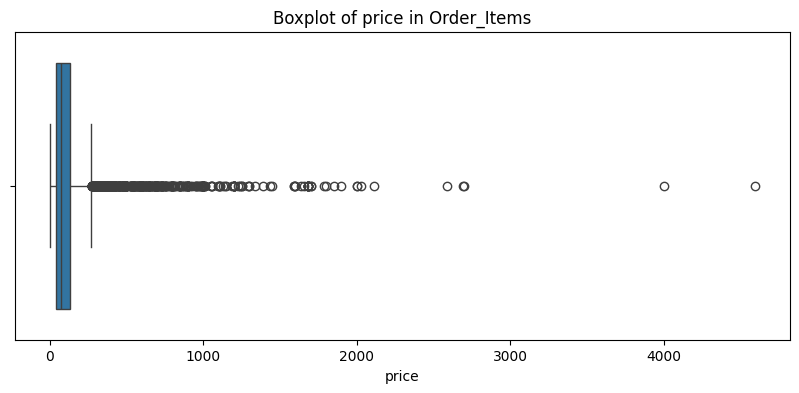

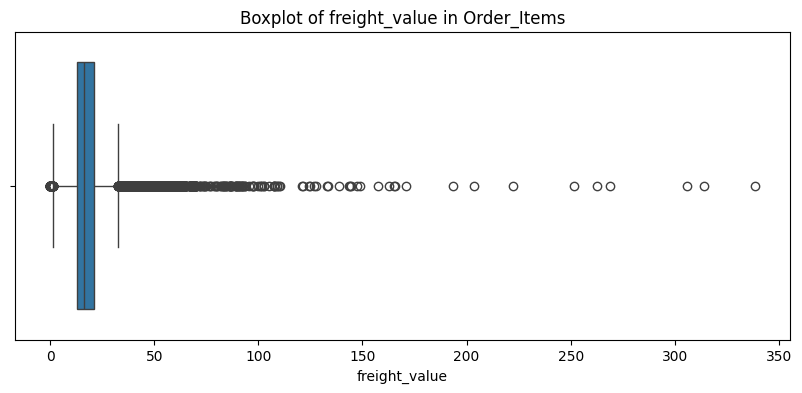

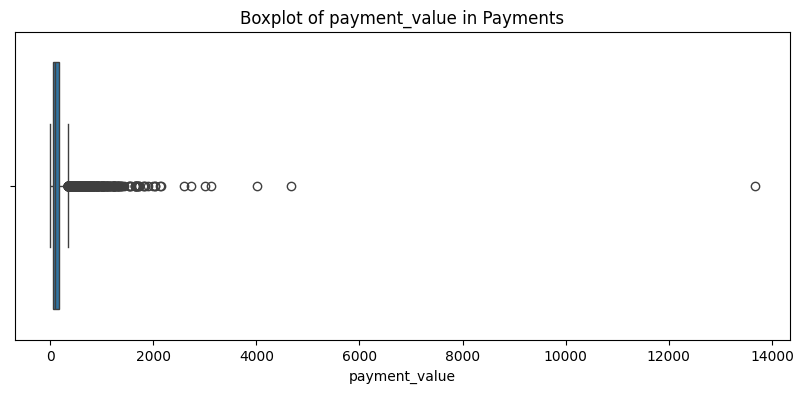

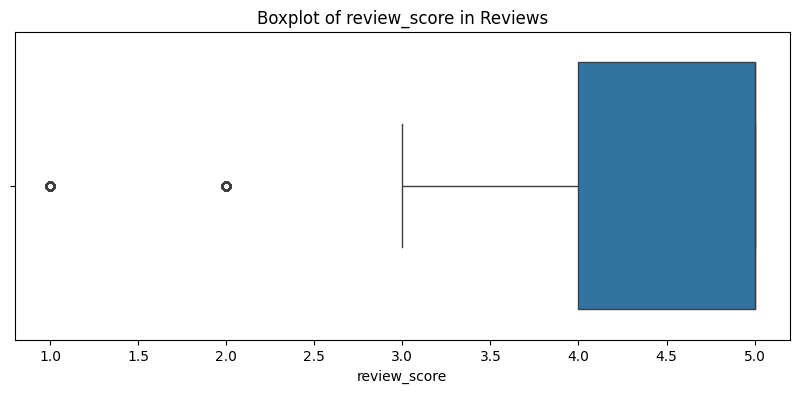

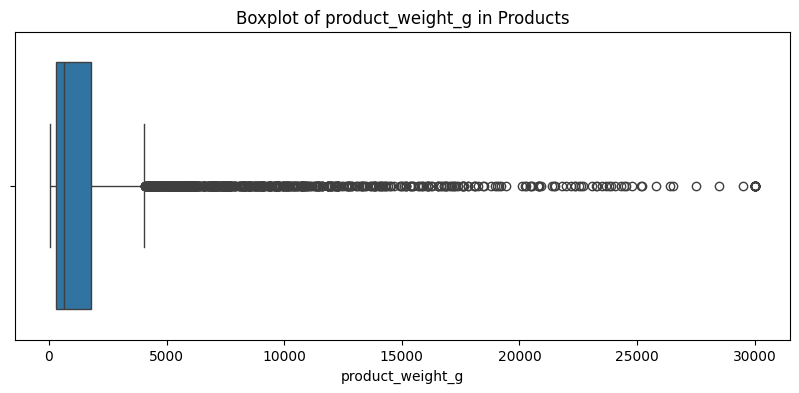

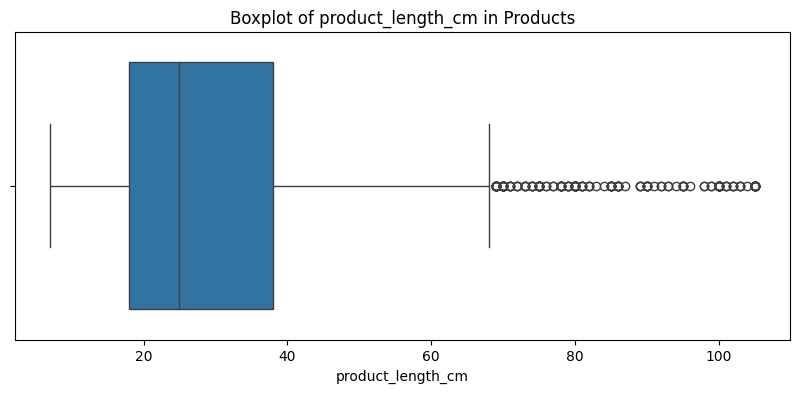

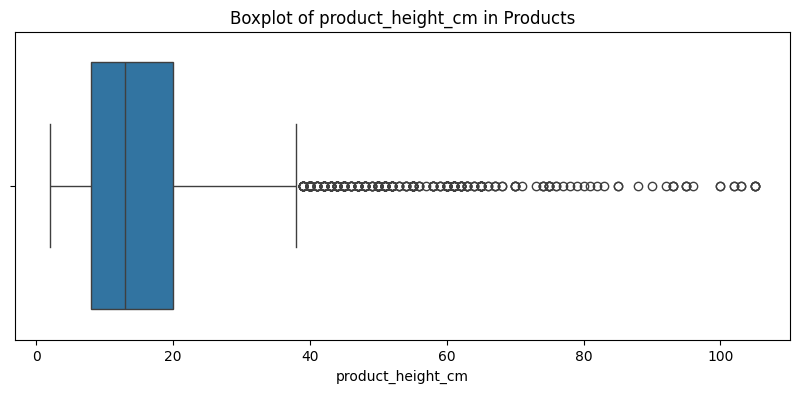

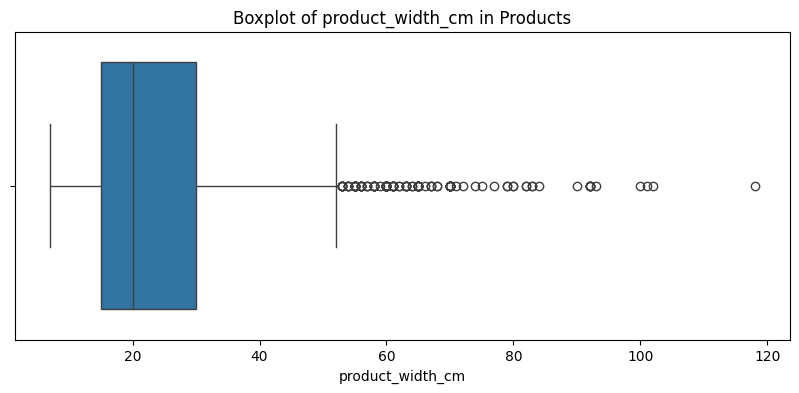

In [ ]:
# Visualize Outliers Using Boxplots


import matplotlib.pyplot as plt
import seaborn as sns


numerical_columns = {
    "Order_Items": ["price", "freight_value"],
    "Payments": ["payment_value"],
    "Reviews": ["review_score"],
    "Products": ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]
}

for sheet_name, columns in numerical_columns.items():

  df = data[sheet_name]

  for col in columns:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col} in {sheet_name}")
    plt.xlabel(col)
    plt.show()

In [ ]:
## Outlier Treatment

# Check extreme Values in Order_Items
order_items_df = data["Order_Items"]

print("Price - Top 10 Highest Values:")
print(order_items_df['price'].nlargest(10))

print("\nFreight Value - Top 10 Highest Values:")
print(order_items_df['freight_value'].nlargest(10))

Price - Top 10 Highest Values:
4922    4590.00
4665    3999.90
2170    2699.00
6072    2690.00
4160    2589.00
3623    2109.90
305     2029.00
4743    1999.99
4471    1999.00
1524    1899.00
Name: price, dtype: float64

Freight Value - Top 10 Highest Values:
1315    338.30
506     314.02
2170    306.06
1629    269.00
5476    262.72
5269    251.50
408     222.38
1513    203.38
8293    193.39
2250    170.86
Name: freight_value, dtype: float64


In [ ]:
# Check Invalid Values in Order_Items

# Correcting to use order_items_df instead of orders_df
print("Price <= 0:")
print((order_items_df['price'] <= 0).sum())

print("\nFreight Value <= 0:")
print((order_items_df['freight_value'] <= 0).sum())

print("\nMinimum Price:")
print(order_items_df['price'].min())

print("\nMinimum Freight Value:")
print(order_items_df['freight_value'].min())

Price <= 0:
0

Freight Value <= 0:
34

Minimum Price:
3.06

Minimum Freight Value:
0.0


In [ ]:
# Display Records With zero Freight Value

zero_freight = order_items_df[
    order_items_df["freight_value"] == 0
]


print("Number of Zero Freight Value Records:", len(zero_freight))
print("\nRecords with Zero Freight Value:")
display(
    zero_freight[
        ['order_id', 'order_item_id',  'price', 'freight_value']
    ].head(20)
)

Number of Zero Freight Value Records: 34

Records with Zero Freight Value:


,order_id,order_item_id,price,freight_value
365,0a0e91f265e0c09af322a473351b61d1,1,106.9,0.0
454,0ca64e59f59b26fb6fb2726f907bb52d,1,99.9,0.0
835,18a0085788733945772c772b19bceed7,1,106.9,0.0
1392,28572ca6264628bbdcd513eb363d6b3a,1,110.0,0.0
1458,2a0e85d19656bd0a3c61a564b010ddd1,1,110.0,0.0
1651,2f669a3575b067a0f0b88d47f53709c2,1,199.0,0.0
1682,2ffd4bf0fbadf9acf274c27d822697ca,1,99.9,0.0
1812,34a0606eca141f2c9ccb352883ee3fbe,1,195.0,0.0
2290,41a6e516105939d8e985a14e2f9d534d,1,110.0,0.0
2653,4c95e64d87f0a8e6c7e8ffc83767df0f,1,69.9,0.0


In [ ]:
# Check Duplicate Records In All Sheets

dataframes = {
    'Orders': data.get('Orders', orders_df),
    'Order_Items': data.get('Order_Items', order_items_df),
    'Payments': data.get('Payments'),
    'Reviews': data.get('Reviews', reviews_df),
    'Products': data.get('Products', products_df),
    'Sellers': data.get('Sellers'),
    'Translation':  data.get('Translation')
}

for sheet_name, df in dataframes.items():
  if df is not None:
    duplicates = df.duplicated().sum()
    print("=" * 50)
    print(f"\nSheet: {sheet_name}")
    print(f"Duplicate Rows: {duplicates}")
  else:
    print("=" * 50)
    print(f"\nSheet: {sheet_name} not found in the dataset.")


Sheet: Orders
Duplicate Rows: 0

Sheet: Order_Items
Duplicate Rows: 0

Sheet: Payments
Duplicate Rows: 0

Sheet: Reviews
Duplicate Rows: 0

Sheet: Products
Duplicate Rows: 0

Sheet: Sellers
Duplicate Rows: 0

Sheet: Translation
Duplicate Rows: 0


In [ ]:
from re import S
# Check Data Types In All Sheets

dataframes = {
    'Orders': data.get('Orders', orders_df),
    'Order_Items': data.get('Order_Items', order_items_df),
    'Payments': data.get('Payments'),
    'Reviews': data.get('Reviews', reviews_df),
    'Products': data.get('Products', products_df),
    'Sellers': data.get('Sellers'),
    'Translation':  data.get('Translation')
}

for sheet_name, df in dataframes.items():

  print("\n" + "=" * 60)
  print(f"Sheet: {sheet_name}")
  print("=" * 60)

  for column in df.columns:
    print(f"{column}: {df[column].dtype}")

  print("\nTotal Columns:", len(df.columns))



Sheet: Orders
order_id: object
customer_id: object
order_status: object
order_purchase_timestamp: datetime64[ns]
order_approved_at: datetime64[ns]
order_delivered_carrier_date: datetime64[ns]
order_delivered_customer_date: datetime64[ns]
order_estimated_delivery_date: datetime64[ns]

Total Columns: 8

Sheet: Order_Items
order_id: object
order_item_id: int64
product_id: object
seller_id: object
shipping_limit_date: datetime64[ns]
price: float64
freight_value: float64

Total Columns: 7

Sheet: Payments
order_id: object
payment_sequential: int64
payment_type: object
payment_installments: int64
payment_value: float64

Total Columns: 5

Sheet: Reviews
review_id: object
order_id: object
review_score: int64
review_comment_title: object
review_comment_message: object
review_creation_date: datetime64[ns]
review_answer_timestamp: datetime64[ns]

Total Columns: 7

Sheet: Products
product_id: object
product_category_name: object
product_name_lenght: float64
product_description_lenght: float64
pro

In [ ]:
# Inspect Float Columns Across All Sheets


for sheet_name, df in dataframes.items():

  print("\n" + "=" * 60)
  print(f"Sheet: {sheet_name}")
  print("=" * 60)

  float_columns = df.select_dtypes(include="float64").columns


  for col in float_columns:
    print("Missing Values:", df[col].isna().sum())
    print("Non-Integer Values:",
          ((df[col].dropna() % 1 != 0).sum()))


Sheet: Orders

Sheet: Order_Items
Missing Values: 0
Non-Integer Values: 6334
Missing Values: 0
Non-Integer Values: 8824

Sheet: Payments
Missing Values: 0
Non-Integer Values: 8091

Sheet: Reviews

Sheet: Products
Missing Values: 0
Non-Integer Values: 0
Missing Values: 0
Non-Integer Values: 0
Missing Values: 0
Non-Integer Values: 0
Missing Values: 0
Non-Integer Values: 0
Missing Values: 0
Non-Integer Values: 0
Missing Values: 0
Non-Integer Values: 0
Missing Values: 0
Non-Integer Values: 0

Sheet: Sellers

Sheet: Translation


In [ ]:
# Outliers Detection Using IQR Method


def detect_outliers(df, columns, sheet_name):


  print(f"\n{"=" * 50}")
  print(f"Sheet: {sheet_name}")
  print(f"{"=" * 50}")

  for col in columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound =  Q1 - 1.5 * IQR

    Upper_bound =  Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) | (df[col] > Upper_bound)
    ]

    print(f"\nColumn: {col}")
    print(f"Lower Bound: {lower_bound}")
    print(f"Upper Bound: {Upper_bound}")
    print(f"Outliers Count: {len(outliers)}")


# Check Order Items

detect_outliers(
    order_items_df,
    ['price', 'freight_value'],
    'Order_Items'
)


Sheet: Order_Items

Column: price
Lower Bound: -99.97499999999994
Upper Bound: 273.0249999999999
Outliers Count: 651

Column: freight_value
Lower Bound: 1.424999999999999
Upper Bound: 32.505
Outliers Count: 959


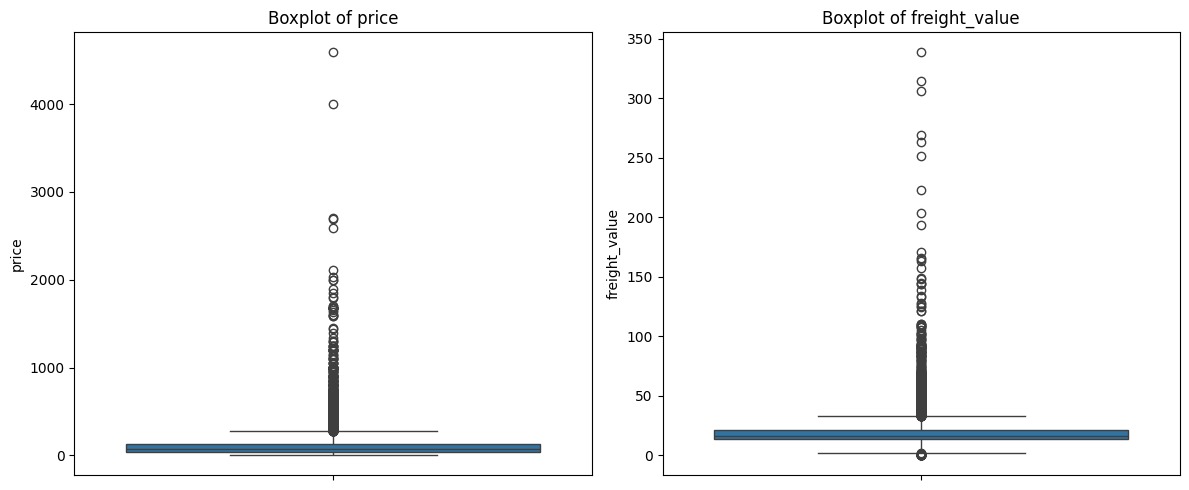

In [ ]:
import seaborn as sns

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

for i, col in enumerate(['price', 'freight_value'], 1):

  plt.subplot(1, 2, i)

  sns.boxplot(y=order_items_df[col])


  plt.title(f"Boxplot of {col}")
  plt.ylabel(col)

plt.tight_layout()
plt.show()

In [ ]:
# Check Data Cleaning Summary

datasets = {'Orders': data.get('Orders', orders_df),
    'Order_Items': data.get('Order_Items', order_items_df),
    'Payments': data.get('Payments'),
    'Reviews': data.get('Reviews', reviews_df),
    'Products': data.get('Products', products_df),
    'Sellers': data.get('Sellers'),
    'Translation':  data.get('Translation')
}


for name, df in datasets.items():
  print(f"\n{'='*45}")
  print(f"Dataset: {name}")
  print(f"Rows: {df.shape[0]}")
  print(f"Columns: {df.shape[1]}")
  print(f"Missing Values: {df.isnull().sum().sum()}")
  print(f"Duplicate Rows: {df.duplicated().sum()}")



  print("\nData Cleaning Summary Completed Successfully!")


Dataset: Orders
Rows: 8002
Columns: 8
Missing Values: 422
Duplicate Rows: 0

Data Cleaning Summary Completed Successfully!

Dataset: Order_Items
Rows: 8942
Columns: 7
Missing Values: 0
Duplicate Rows: 0

Data Cleaning Summary Completed Successfully!

Dataset: Payments
Rows: 8406
Columns: 5
Missing Values: 0
Duplicate Rows: 0

Data Cleaning Summary Completed Successfully!

Dataset: Reviews
Rows: 7986
Columns: 7
Missing Values: 0
Duplicate Rows: 0

Data Cleaning Summary Completed Successfully!

Dataset: Products
Rows: 5622
Columns: 9
Missing Values: 0
Duplicate Rows: 0

Data Cleaning Summary Completed Successfully!

Dataset: Sellers
Rows: 1491
Columns: 4
Missing Values: 0
Duplicate Rows: 0

Data Cleaning Summary Completed Successfully!

Dataset: Translation
Rows: 71
Columns: 2
Missing Values: 0
Duplicate Rows: 0

Data Cleaning Summary Completed Successfully!


In [ ]:
# Check Missing Values In Orders Dataset


print("Missing Values Per Columns:")
print(orders_df.isnull().sum())


print("\nMissing Values Percentage:")
print((orders_df.isnull().sum() / len(orders_df) * 100).round(2))

Missing Values Per Columns:
order_id                           0
customer_id                        0
order_status                       0
order_purchase_timestamp           0
order_approved_at                 16
order_delivered_carrier_date     149
order_delivered_customer_date    257
order_estimated_delivery_date      0
dtype: int64

Missing Values Percentage:
order_id                         0.00
customer_id                      0.00
order_status                     0.00
order_purchase_timestamp         0.00
order_approved_at                0.20
order_delivered_carrier_date     1.86
order_delivered_customer_date    3.21
order_estimated_delivery_date    0.00
dtype: float64


In [ ]:
# Analyze Missing Values by Order Status

Missing_analysis = orders_df.groupby('order_status').agg(
    Total_Orders=('order_id', 'count'),
    Missing_values=('order_approved_at',
                    lambda x: x.isnull().sum()),
    Missing_Carrier=('order_delivered_carrier_date',
                    lambda x: x.isnull().sum()),
    Missing_Delivered=('order_delivered_customer_date',
                      lambda x: x.isnull().sum())
)


print(Missing_analysis)


              Total_Orders  Missing_values  Missing_Carrier  Missing_Delivered
order_status                                                                  
canceled                47              15               44                 47
delivered             7746               1                0                  1
invoiced                20               0               20                 20
processing              29               0               29                 29
shipped                104               0                0                104
unavailable             56               0               56                 56


In [ ]:
#Inspect Missing Dates in Delivered Orders


delivered_missing = orders_df[
    (orders_df['order_status'] == 'delivered') &
    (
        orders_df['order_approved_at'].isnull() |
        orders_df['order_delivered_customer_date'].isnull()
    )
]

print(delivered_missing.to_string(index=False))

                        order_id                      customer_id order_status order_purchase_timestamp   order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date
d77031d6a3c8a52f019764e68f211c69 0bf35cac6cc7327065da879e2d90fae8    delivered      2017-02-18 11:04:19                 NaT          2017-02-23 07:23:36           2017-03-02 16:15:23                    2017-03-22
f5dd62b788049ad9fc0526e3ad11a097 5e89028e024b381dc84a13a3570decb4    delivered      2018-06-20 06:58:43 2018-06-20 07:19:05          2018-06-25 08:05:00                           NaT                    2018-07-16


In [ ]:
# count Missing Dates In Deliverd Orders


print("Missing Dates in Delivered Orders:")

print(delivered_missing[
    ['order_approved_at',
     'order_delivered_carrier_date',
     'order_delivered_customer_date']
].isnull().sum())

Missing Dates in Delivered Orders:
order_approved_at                1
order_delivered_carrier_date     0
order_delivered_customer_date    1
dtype: int64


In [ ]:
# identify Outliers Using IQR Method

# Price Outliers
Q1_price = order_items_df['price'].quantile(0.25)
Q3_price = order_items_df['price'].quantile(0.75)

IQR_price = Q3_price - Q1_price

lower_bound_price = Q1_price - 1.5 * IQR_price
upper_bound_price = Q3_price + 1.5 * IQR_price

order_items_df['price_outlier'] = (
    (order_items_df['price'] < lower_bound_price) |
    (order_items_df['price'] > upper_bound_price)
)

# Freight Value Outliers
Q1_freight = order_items_df['freight_value'].quantile(0.25)
Q3_freight = order_items_df['freight_value'].quantile(0.75)

IQR_freight = Q3_freight - Q1_freight

lower_bound_freight = Q1_freight - 1.5 * IQR_freight
upper_bound_freight = Q3_freight + 1.5 * IQR_freight

order_items_df['freight_outlier'] = (
    (order_items_df['freight_value'] < lower_bound_freight) |
    (order_items_df['freight_value'] > upper_bound_freight)
)


#count Outliers

print("Price Outliers Count:", order_items_df['price_outlier'].sum())
print("Freight Value Outliers Count:", order_items_df['freight_outlier'].sum())

Price Outliers Count: 651
Freight Value Outliers Count: 959


In [ ]:
# Display Highst Price Values


print("Top 10 Highest Price Values:")
print(order_items_df.nlargest(10, 'price')['price'])

# Display Highst Freight Values

print("\nTop 10 Highest Freight Values:")
print(order_items_df.nlargest(10, 'freight_value')['freight_value'])

Top 10 Highest Price Values:
4922    4590.00
4665    3999.90
2170    2699.00
6072    2690.00
4160    2589.00
3623    2109.90
305     2029.00
4743    1999.99
4471    1999.00
1524    1899.00
Name: price, dtype: float64

Top 10 Highest Freight Values:
1315    338.30
506     314.02
2170    306.06
1629    269.00
5476    262.72
5269    251.50
408     222.38
1513    203.38
8293    193.39
2250    170.86
Name: freight_value, dtype: float64


In [ ]:
# Inspect Highst Price Records


print("Top 10 Highst Price Records:")


print(
    order_items_df.nlargest(10, 'price')[
    ['order_id', 'product_id', 'seller_id', 'price', 'freight_value']
    ]
)


#inspect Highest Freight Records


print("\nTop 10 Highst Freight Records:")


print(
    order_items_df.nlargest(10, 'freight_value')[
    ['order_id', 'product_id', 'seller_id', 'price', 'freight_value']
    ] )

Top 10 Highst Price Records:
                              order_id                        product_id  \
4922  8dbc85d1447242f3b127dda390d56e19  259037a6a41845e455183f89c5035f18   
4665  86c4eab1571921a6a6e248ed312f5a5a  6902c1962dd19d540807d0ab8fade5c6   
2170  3dd5626c63f493f8b8f8788c2be24baa  3a1855685a49813f60e6193864f7215e   
6072  afc58387b17fa794fd73b0773a9f6ea7  3ecf69ee1fe21cfd40b30cbea549e563   
4160  78ce53a063eb2907f9727aac2c678339  3ecf69ee1fe21cfd40b30cbea549e563   
3623  6907ea7150759a085c8ed75a55aeb90d  b0b727747746e677a470d0948bb68520   
305   086f8f18f98299e22931d762c63db2b8  23e44bcf966914b366c7e28f13327dfe   
4743  88ce73cc24548143016810f81a9e53d4  fd0065af7f09af4b82a0ca8f3eed1852   
4471  80ac215e5fbfa62e737e8d47e2287b2c  5183344b5357029cfd88c7f511ed876d   
1524  2be6e5724bc6705448e72ac1b13141c4  67a1e52f1184a4ffecff3b0a80d00889   

                             seller_id    price  freight_value  
4922  c72de06d72748d1a0dfb2125be43ba63  4590.00          91.78  
4665

In [ ]:
# Check Invalid Values


# Check price

print("Price Negative Values",
      (order_items_df['price'] < 0).sum())


print("Price Zero Values:",
      (order_items_df['price'] == 0).sum())

#check Freight Value

print("\nFreight Negative Values:",
      (order_items_df['freight_value'] < 0).sum())

print("Freight Zero Values:",
      (order_items_df['freight_value'] == 0).sum())

Price Negative Values 0
Price Zero Values: 0

Freight Negative Values: 0
Freight Zero Values: 34


In [ ]:
# Inspect Zero Freight Value Records


zero_freight = order_items_df[
    order_items_df["freight_value"] == 0
]


print("Number of Zero Freight Value Records:", len(zero_freight))


print("\nZero Freight Records Details:")

print(
    zero_freight[
        ['order_id', 'product_id', 'seller_id',
         'price', 'freight_value']
    ]
)

Number of Zero Freight Value Records: 34

Zero Freight Records Details:
                              order_id                        product_id  \
365   0a0e91f265e0c09af322a473351b61d1  53b36df67ebb7c41585e8d54d6772e08   
454   0ca64e59f59b26fb6fb2726f907bb52d  53b36df67ebb7c41585e8d54d6772e08   
835   18a0085788733945772c772b19bceed7  53b36df67ebb7c41585e8d54d6772e08   
1392  28572ca6264628bbdcd513eb363d6b3a  53b36df67ebb7c41585e8d54d6772e08   
1458  2a0e85d19656bd0a3c61a564b010ddd1  53b36df67ebb7c41585e8d54d6772e08   
1651  2f669a3575b067a0f0b88d47f53709c2  7a10781637204d8d10485c71a6108a2e   
1682  2ffd4bf0fbadf9acf274c27d822697ca  53b36df67ebb7c41585e8d54d6772e08   
1812  34a0606eca141f2c9ccb352883ee3fbe  f1c7f353075ce59d8a6f3cf58f419c9c   
2290  41a6e516105939d8e985a14e2f9d534d  53b36df67ebb7c41585e8d54d6772e08   
2653  4c95e64d87f0a8e6c7e8ffc83767df0f  aca2eb7d00ea1a7b8ebd4e68314663af   
2853  52213ce438ca7a21ce81bc3d48a3d4e3  aca2eb7d00ea1a7b8ebd4e68314663af   
3870  70195fea2b

In [ ]:
# Final Data Quality Check

datasets = {'Orders': data.get('Orders', orders_df),
    'Order_Items': data.get('Order_Items', order_items_df),
    'Payments': data.get('Payments'),
    'Reviews': data.get('Reviews', reviews_df),
    'Products': data.get('Products', products_df),
    'Sellers': data.get('Sellers'),
    'Translation':  data.get('Translation')

}


for name, df in datasets.items():
  print(f"\n{'='*40}")
  print(f"Dataset: {name}")
  print(f"{'='*40}")

  print(f"Rows: {df.shape[0]}")
  print(f"Columns: {df.shape[1]}")
  print(f"Missing Values: {df.isnull().sum().sum()}")
  print(f"Duplicate Rows: {df.duplicated().sum()}")





Dataset: Orders
Rows: 8002
Columns: 8
Missing Values: 422
Duplicate Rows: 0

Dataset: Order_Items
Rows: 8942
Columns: 9
Missing Values: 0
Duplicate Rows: 0

Dataset: Payments
Rows: 8406
Columns: 5
Missing Values: 0
Duplicate Rows: 0

Dataset: Reviews
Rows: 7986
Columns: 7
Missing Values: 0
Duplicate Rows: 0

Dataset: Products
Rows: 5622
Columns: 9
Missing Values: 0
Duplicate Rows: 0

Dataset: Sellers
Rows: 1491
Columns: 4
Missing Values: 0
Duplicate Rows: 0

Dataset: Translation
Rows: 71
Columns: 2
Missing Values: 0
Duplicate Rows: 0


In [ ]:
# Check All load Datasets Variables


print([name for name in globals() if 'customer' in name.lower()])

[]


In [ ]:
print(pd.ExcelFile(file_path).sheet_names)

['Orders', 'Order_Items', 'Payments', 'Reviews', 'Customers', 'Products', 'Sellers', 'Translation']


In [ ]:
#load Customer Dataset

customer_df = pd.read_excel(file_path, sheet_name='Customers')

print("Customers Dataset Loaded Successfully!")
print("Rows:", customer_df.shape[0])
print("Columns:", customer_df.shape[1])


display(customer_df.head())

Customers Dataset Loaded Successfully!
Rows: 8002
Columns: 5


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
1,879864dab9bc3047522c92c82e1212b8,4c93744516667ad3b8f1fb645a3116a4,89254,jaragua do sul,SC
2,41c8f4b570869791379a925899a6af8a,fe3634ccefbcdb0537b45fd589e32e8e,7170,guarulhos,SP
3,8fcaa9368903f3a9a28aeaff28c14638,3af0b2f7654f613ff1527b997a2ac57e,79804,dourados,MS
4,aa9f03ecd3728c9bd12e6d962c66c7cb,b03e9d9818ee170e9d6b983803c7d406,75388,trindade,GO


In [ ]:
datasets['Customers'] = customer_df


print("Total Datasets:", len(datasets))

print("Dataset Names:", list(datasets.keys()))

Total Datasets: 8
Dataset Names: ['Orders', 'Order_Items', 'Payments', 'Reviews', 'Products', 'Sellers', 'Translation', 'Customers']


In [ ]:
# Export All Cleaned Datasets

output_file = '/content/olist_Cleaned_Dataset.xlsx'

print("Datasets Before Export:")
print(list(datasets.keys()))

with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
    for name, df in datasets.items():
        df.to_excel(writer, sheet_name=name[:31], index=False)

print("\nAll Cleaned Datasets Exported Successfully!")
print("File Name:", output_file)

Datasets Before Export:
['Orders', 'Order_Items', 'Payments', 'Reviews', 'Products', 'Sellers', 'Translation', 'Customers']

All Cleaned Datasets Exported Successfully!
File Name: /content/olist_Cleaned_Dataset.xlsx


In [ ]:
from google.colab import output
output_file = '/content/olist_Cleaned_Dataset.xlsx'

excel_file = pd.ExcelFile(output_file)

print("Exported Sheet Names:")
print(excel_file.sheet_names)

print("\nTotal Sheets:", len(excel_file.sheet_names))

for sheet in excel_file.sheet_names:
  df = pd.read_excel(output_file, sheet_name=sheet)

  print(f"\nDataset: {sheet}")
  print("Rows:", df.shape[0])
  print("Columns:", df.shape[1])
  print("Missing Values:", df.isnull().sum().sum())
  print("Duplicate Rows:", df.duplicated().sum())

Exported Sheet Names:
['Orders', 'Order_Items', 'Payments', 'Reviews', 'Products', 'Sellers', 'Translation', 'Customers']

Total Sheets: 8

Dataset: Orders
Rows: 8002
Columns: 8
Missing Values: 422
Duplicate Rows: 0

Dataset: Order_Items
Rows: 8942
Columns: 9
Missing Values: 0
Duplicate Rows: 0

Dataset: Payments
Rows: 8406
Columns: 5
Missing Values: 0
Duplicate Rows: 0

Dataset: Reviews
Rows: 7986
Columns: 7
Missing Values: 0
Duplicate Rows: 0

Dataset: Products
Rows: 5622
Columns: 9
Missing Values: 0
Duplicate Rows: 0

Dataset: Sellers
Rows: 1491
Columns: 4
Missing Values: 0
Duplicate Rows: 0

Dataset: Translation
Rows: 71
Columns: 2
Missing Values: 0
Duplicate Rows: 0

Dataset: Customers
Rows: 8002
Columns: 5
Missing Values: 0
Duplicate Rows: 0


In [ ]:
from google.colab import files

files.download('/content/olist_Cleaned_Dataset.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>